**DAV 6150 Project 1: Regression Analysis on NY State High School Dropout Metrics**

Team/Author(s): <Saugat Sijapati, Sreshta Kusuru, Emmanuel Olimi Kasigazi, Bhavani Danthuri, Nicolette Mtisi>



### **1. Introduction**

The objective of this project is to apply the data science modeling lifecycle to predict the number of student dropouts (`dropout_cnt`) within specific NY State school districts and student subgroup combinations for the 2018-2019 school year.

The target variable, `dropout_cnt`, is a non-negative integer, making this a count data regression problem. Therefore, the primary modeling techniques will be **Poisson** and **Negative Binomial** regression. These models are specifically designed for count data and will be compared against a baseline **Multiple Linear Regression (MLR)** model to evaluate their effectiveness. The project will encompass a full workflow, including data cleaning, exploratory data analysis (EDA), feature engineering, model construction, and performance evaluation.


In [4]:
# ==============================================================================
# 1. SETUP: IMPORT LIBRARIES AND LOAD DATA
# ==============================================================================

# --- Import necessary libraries ---

# Core data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn for data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Statsmodels for regression modeling
import statsmodels.api as sm
from statsmodels.genmod.generalized_linear_model import GLM
from statsmodels.genmod import families

# Scikit-learn for model evaluation metrics
from sklearn.metrics import mean_squared_error, r2_score

# Utility to suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# --- Define file paths and key variables ---

# The URL path to the raw CSV data file
DATA_URL = "https://github.com/nic-stack/DAV6150-/raw/refs/heads/main/Project1_Data.csv"

# The name of the target variable we want to predict
TARGET_VAR = 'dropout_cnt'

# The name of the exposure variable (cohort size), used as an offset in models
EXPOSURE_VAR = 'enroll_cnt'

# --- Load the dataset ---

# Read the data from the URL into a pandas DataFrame
df = pd.read_csv(DATA_URL)

# --- Initial Inspection ---

# Print the dimensions of the dataframe (rows, columns)
print("Shape of the initial dataset:")
print(df.shape)
print("\nFirst 5 rows of the dataset:")
# Display the first 5 rows to verify it loaded correctly
display(df.head())

# Display a concise summary of the DataFrame, including data types and non-null counts
print("\nDataset Information:")
df.info()

Shape of the initial dataset:
(73152, 29)

First 5 rows of the dataset:


,report_school_year,aggregation_index,aggregation_type,aggregation_name,nrc_code,nrc_desc,county_code,county_name,nyc_ind,membership_desc,...,reg_adv_cnt,reg_adv_pct,non_diploma_credential_cnt,non_diploma_credential_pct,still_enr_cnt,still_enr_pct,ged_cnt,ged_pct,dropout_cnt,dropout_pct
0,2018-19,3,District,ALBANY CITY SCHOOL DISTRICT,3,Urban-Suburban High Needs,1,ALBANY,0,2013 Total Cohort - 6 Year Outcome,...,91,14%,16,2%,30,5%,0,0%,148,22%
1,2018-19,3,District,ALBANY CITY SCHOOL DISTRICT,3,Urban-Suburban High Needs,1,ALBANY,0,2013 Total Cohort - 6 Year Outcome,...,47,15%,2,1%,11,3%,0,0%,65,20%
2,2018-19,3,District,ALBANY CITY SCHOOL DISTRICT,3,Urban-Suburban High Needs,1,ALBANY,0,2013 Total Cohort - 6 Year Outcome,...,44,13%,14,4%,19,6%,0,0%,83,25%
3,2018-19,3,District,ALBANY CITY SCHOOL DISTRICT,3,Urban-Suburban High Needs,1,ALBANY,0,2013 Total Cohort - 6 Year Outcome,...,-,-,-,-,-,-,-,-,-,-
4,2018-19,3,District,ALBANY CITY SCHOOL DISTRICT,3,Urban-Suburban High Needs,1,ALBANY,0,2013 Total Cohort - 6 Year Outcome,...,23,6%,10,3%,18,5%,0,0%,91,25%



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73152 entries, 0 to 73151
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   report_school_year          73152 non-null  object
 1   aggregation_index           73152 non-null  int64 
 2   aggregation_type            73152 non-null  object
 3   aggregation_name            73152 non-null  object
 4   nrc_code                    73152 non-null  int64 
 5   nrc_desc                    73152 non-null  object
 6   county_code                 73152 non-null  int64 
 7   county_name                 73152 non-null  object
 8   nyc_ind                     73152 non-null  int64 
 9   membership_desc             73152 non-null  object
 10  subgroup_code               73152 non-null  int64 
 11  subgroup_name               73152 non-null  object
 12  enroll_cnt                  73152 non-null  object
 13  grad_cnt                

In [5]:
df.shape

(73152, 29)

### **2. Exploratory Data Analysis (EDA) and Data Preparation**

In this section, we perform a comprehensive exploratory data analysis to understand the structure, integrity, and underlying patterns within the dataset. The primary goals are to clean the data, diagnose key statistical properties relevant to regression modeling, and prepare the dataset for the feature engineering phase.


### 2.1 Data Cleaning and Integrity: Handling Suppressed Data

The raw NYSED dataset uses a dash (`-`) as a placeholder for suppressed data. According to NYSED policy, data is suppressed for confidentiality when cohort sizes are too small to yield statistically reliable results.

**Justification:** Our models must be trained on valid, numeric data. Therefore, the first step is to convert these non-numeric placeholders into a standard `NaN` (Not a Number) format. Subsequently, any rows where our target variable, `dropout_cnt`, is `NaN` must be removed, as they provide no value for training a predictive model. We will also drop metadata columns that are redundant (e.g., code columns where text descriptions exist) or not useful as predictors (e.g., report year, which is constant).

[Why are there dashes instead of numbers in some places in the New York State Report Cards](https://datasupport.nysed.gov/hc/en-us/articles/115000765546-Why-are-there-dashes-instead-of-numbers-in-some-places-in-the-New-York-State-Report-Cards-and-s-instead-of-numbers-in-the-report-card-database#:~:text=When%20fewer%20than%20five%20students%20in%20a%20group,report%20cards%20are%20indicated%20with%20a%20dash%20%28%E2%80%93%29.)

Furthermore, we will exclude the `aggregation_name` column. This feature, which identifies the specific school district, has over 680 unique categories. Including such a high-cardinality feature would dramatically increase the dimensionality of our dataset after one-hot encoding, making the model unnecessarily complex and likely leading to overfitting. While more advanced techniques like target encoding exist, for this analysis we will focus on more generalizable features like resource capacity (`nrc_desc`) and location (`nyc_ind`).

In [8]:
# ==============================================================================
# 2.1 DATA CLEANING: CONVERT SUPPRESSED VALUES AND DROP IRRELEVANT COLUMNS
# ==============================================================================

# --- 1. Convert placeholders ('-') to NaN and cast numeric columns ---

# Create a list of all columns that should be numeric (contain 'cnt' or 'pct').
numeric_cols = [col for col in df.columns if 'cnt' in col or 'pct' in col]

# Loop through each identified numeric column.
for col in numeric_cols:
    # Replace the non-numeric dash '-' with NumPy's NaN.
    # pd.to_numeric converts the column to a numeric type (e.g., float).
    # 'errors='coerce'' will turn any values that cannot be converted into NaN.
    df[col] = pd.to_numeric(df[col].replace('-', np.nan), errors='coerce')

# --- 2. Filter rows with suppressed target data ---

# Store the original number of rows to calculate how many are dropped.
original_row_count = df.shape[0]

# Drop all rows where the TARGET_VAR ('dropout_cnt') is NaN.
# .copy() is used to avoid a SettingWithCopyWarning.
df_clean = df.dropna(subset=[TARGET_VAR]).copy()

# Store the new number of rows.
cleaned_row_count = df_clean.shape[0]

# --- 3. Drop non-predictive or redundant metadata columns ---

# Define the list of columns to remove.
# We now add 'aggregation_name' due to its high cardinality.
cols_to_drop = [
    'report_school_year', 'aggregation_index', 'aggregation_type',
    'aggregation_name', #
    'nrc_code', 'county_code', 'subgroup_code', 'membership_desc'
]

# Drop the specified columns from the cleaned DataFrame.
df_clean.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# --- 4. Report the results of the cleaning process ---

print(f"Shape after filtering suppressed data: {df_clean.shape}")
print(f"Total rows dropped due to suppression: {original_row_count - cleaned_row_count}")

Shape after filtering suppressed data: (39674, 21)
Total rows dropped due to suppression: 33478


### 2.2 Univariate Analysis: Target Distribution and Overdispersion
Before focusing on the target variable and feature interactions, it's a valuable EDA practice to visually inspect the distribution of each individual numeric variable. This helps us understand the scale, skewness, and presence of outliers for each potential predictor.

For each numeric column, we will generate two plots side-by-side:
*   **Boxplot:** To quickly identify the median, quartiles, and outliers.
*   **Histogram:** To visualize the shape of the data's distribution.

A core assumption of **Poisson Regression** is that the mean and variance of the target variable are equal (a property known as equidispersion). If the variance is significantly larger than the mean, the data is **overdispersed**.

**Justification:** Overdispersion violates the assumptions of the Poisson model, often leading to underestimated standard errors and an incorrect assessment of the model's fit. **Negative Binomial Regression** is a more flexible alternative that is specifically designed to handle overdispersed count data. By examining the distribution and calculating the Overdispersion Ratio (Variance / Mean), we can determine which modeling approach will be more appropriate.

--- Generating Univariate Plots for All Numeric Features ---
This systematic review is crucial for identifying skewness and outliers as noted by the team.
--------------------------------------------------

Analyzing distribution for: 'nyc_ind'
count    39674.000000
mean         0.085245
std          0.279249
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: nyc_ind, dtype: float64


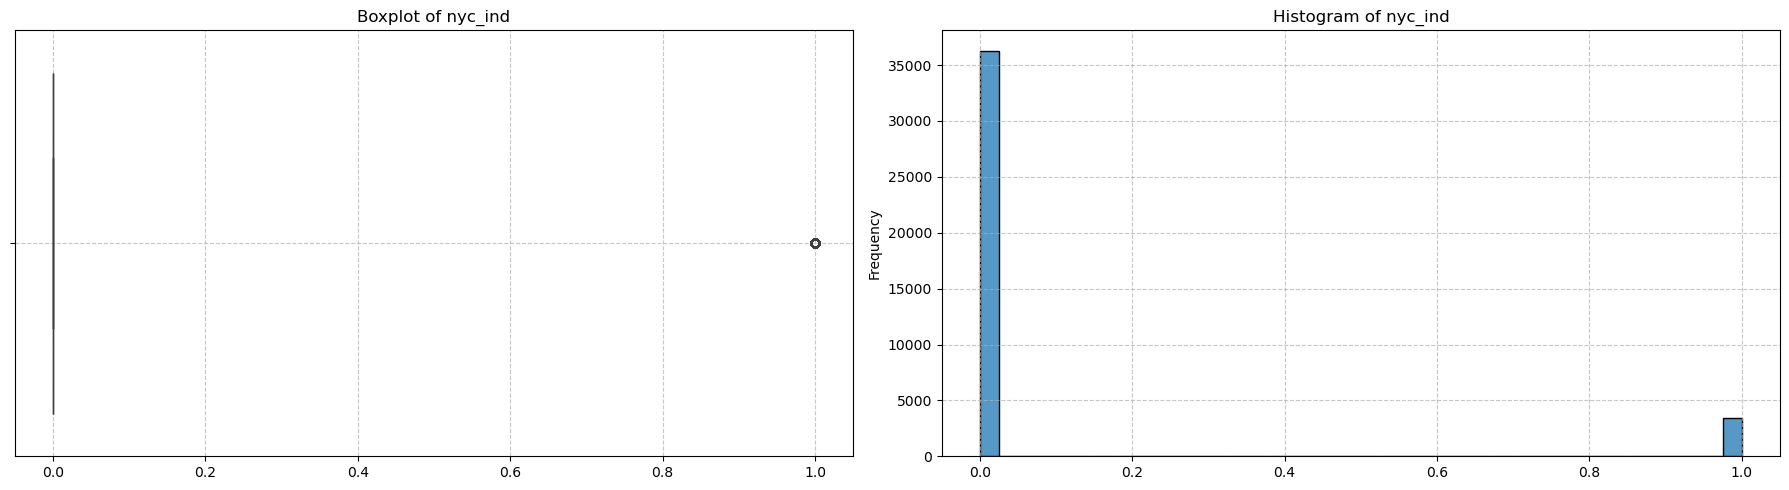

--------------------------------------------------

Analyzing distribution for: 'enroll_cnt'
count    39674.000000
mean       192.120079
std        439.972474
min          5.000000
25%         25.000000
50%         66.000000
75%        179.000000
max       9176.000000
Name: enroll_cnt, dtype: float64


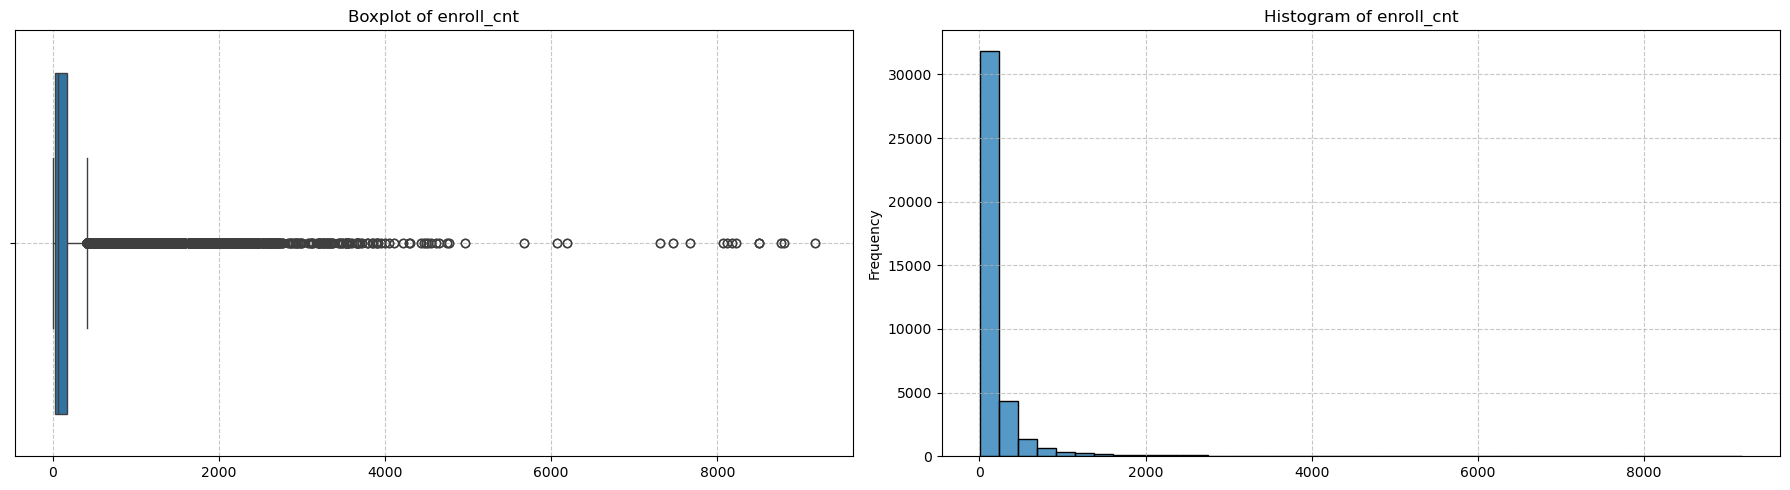

--------------------------------------------------

Analyzing distribution for: 'grad_cnt'
count    39674.000000
mean       161.178354
std        361.294773
min          0.000000
25%         20.000000
50%         57.000000
75%        156.000000
max       7540.000000
Name: grad_cnt, dtype: float64


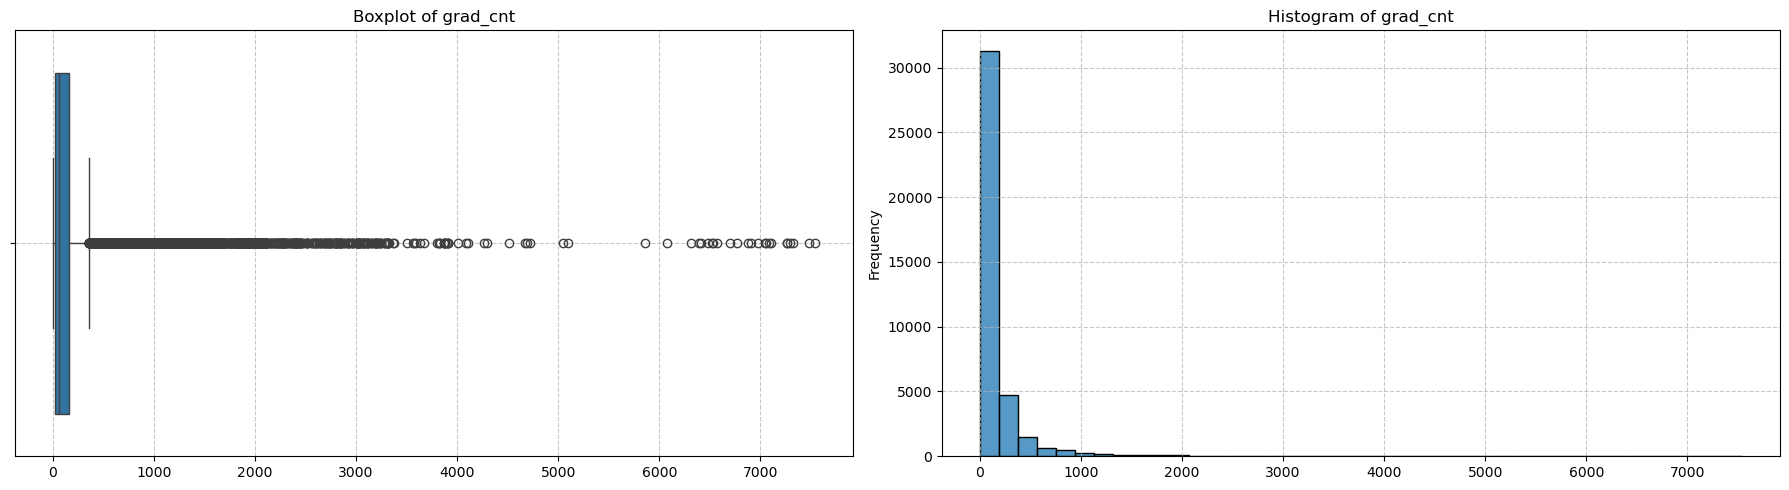

--------------------------------------------------

Analyzing distribution for: 'grad_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: grad_pct, dtype: float64

--> SKIPPING PLOT for 'grad_pct' because it contains no valid data after cleaning.
--------------------------------------------------

Analyzing distribution for: 'local_cnt'
count    39674.000000
mean        12.340903
std         32.046302
min          0.000000
25%          1.000000
50%          4.000000
75%         10.000000
max        557.000000
Name: local_cnt, dtype: float64


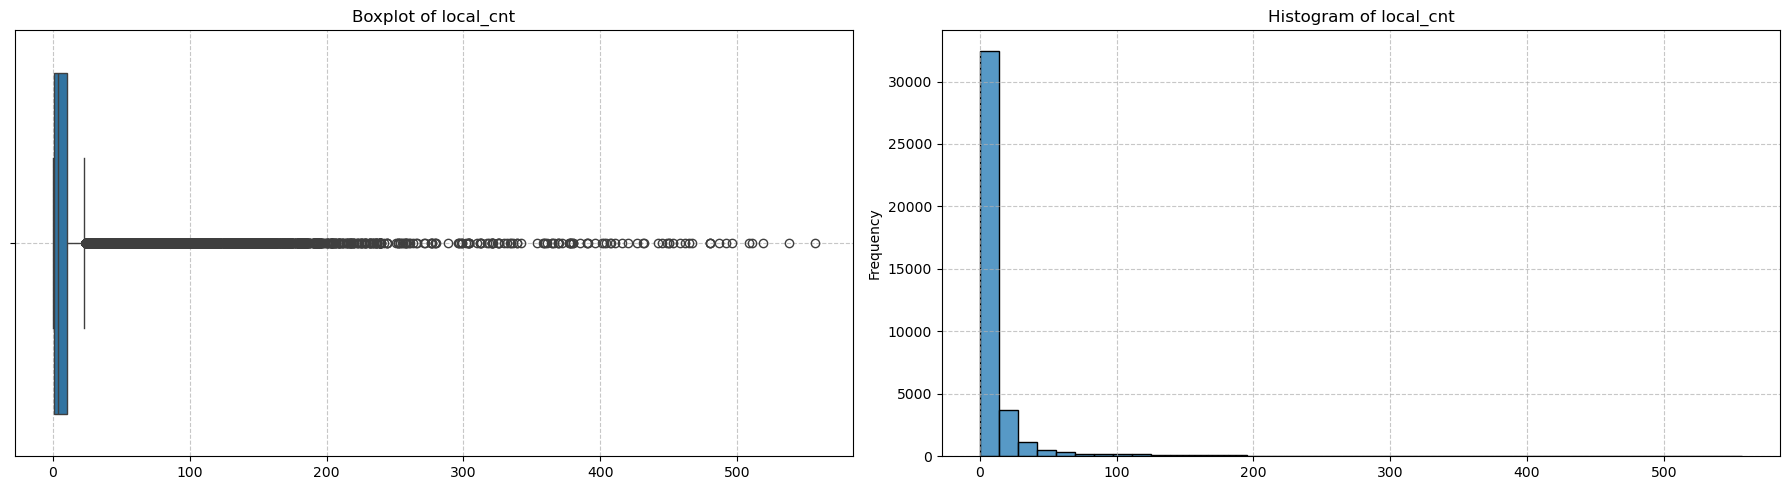

--------------------------------------------------

Analyzing distribution for: 'local_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: local_pct, dtype: float64

--> SKIPPING PLOT for 'local_pct' because it contains no valid data after cleaning.
--------------------------------------------------

Analyzing distribution for: 'reg_cnt'
count    39674.000000
mean        86.804708
std        225.795826
min          0.000000
25%         10.000000
50%         27.000000
75%         69.000000
max       4752.000000
Name: reg_cnt, dtype: float64


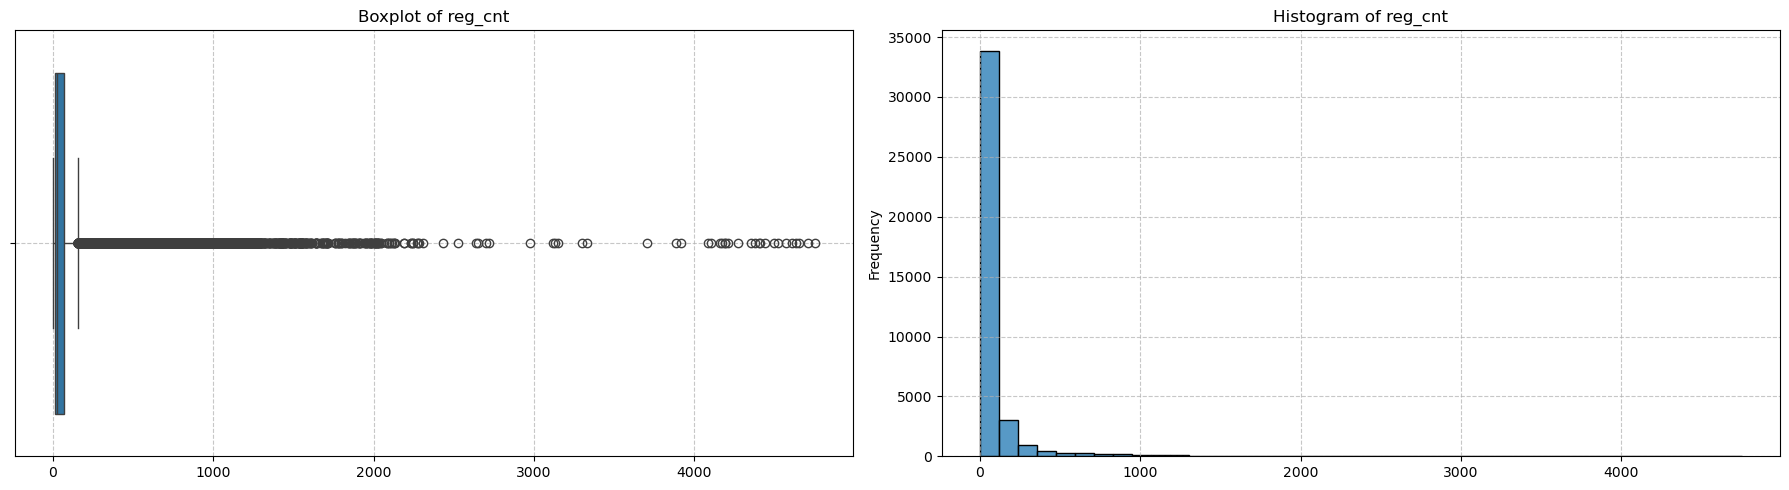

--------------------------------------------------

Analyzing distribution for: 'reg_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: reg_pct, dtype: float64

--> SKIPPING PLOT for 'reg_pct' because it contains no valid data after cleaning.
--------------------------------------------------

Analyzing distribution for: 'reg_adv_cnt'
count    39674.000000
mean        62.032742
std        132.777866
min          0.000000
25%          4.000000
50%         18.000000
75%         62.000000
max       2231.000000
Name: reg_adv_cnt, dtype: float64


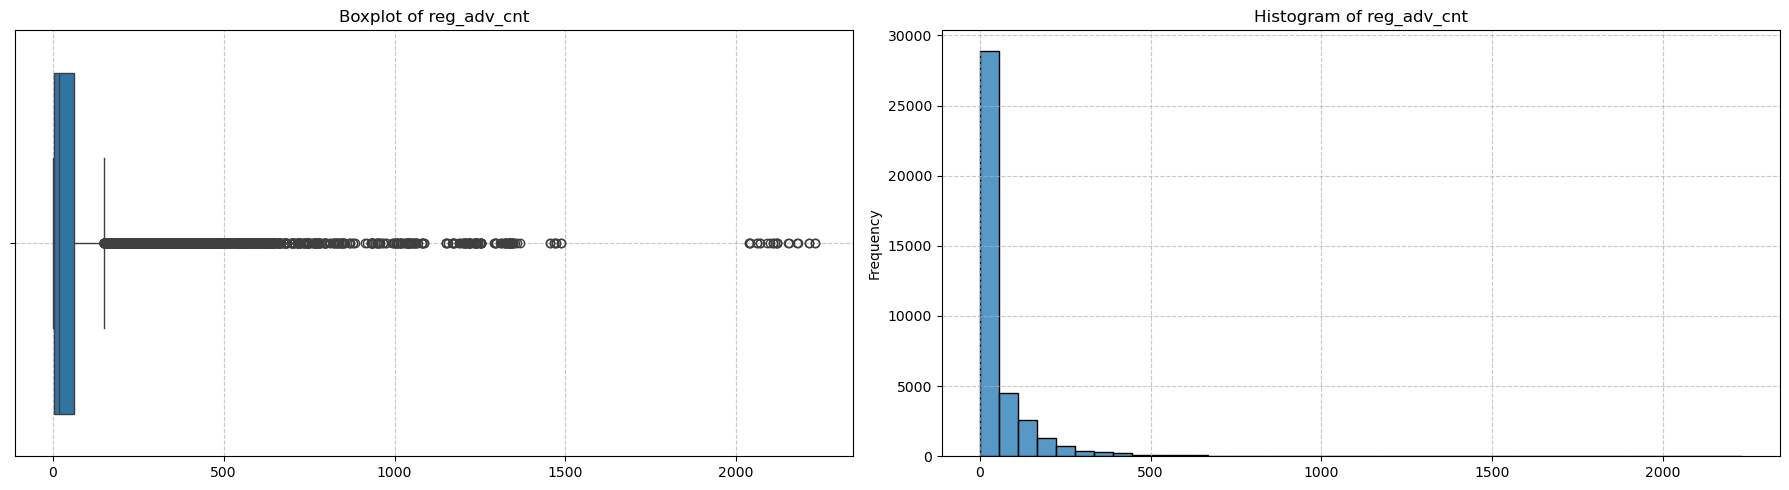

--------------------------------------------------

Analyzing distribution for: 'reg_adv_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: reg_adv_pct, dtype: float64

--> SKIPPING PLOT for 'reg_adv_pct' because it contains no valid data after cleaning.
--------------------------------------------------

Analyzing distribution for: 'non_diploma_credential_cnt'
count    39674.000000
mean         1.924485
std          6.498913
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max        279.000000
Name: non_diploma_credential_cnt, dtype: float64


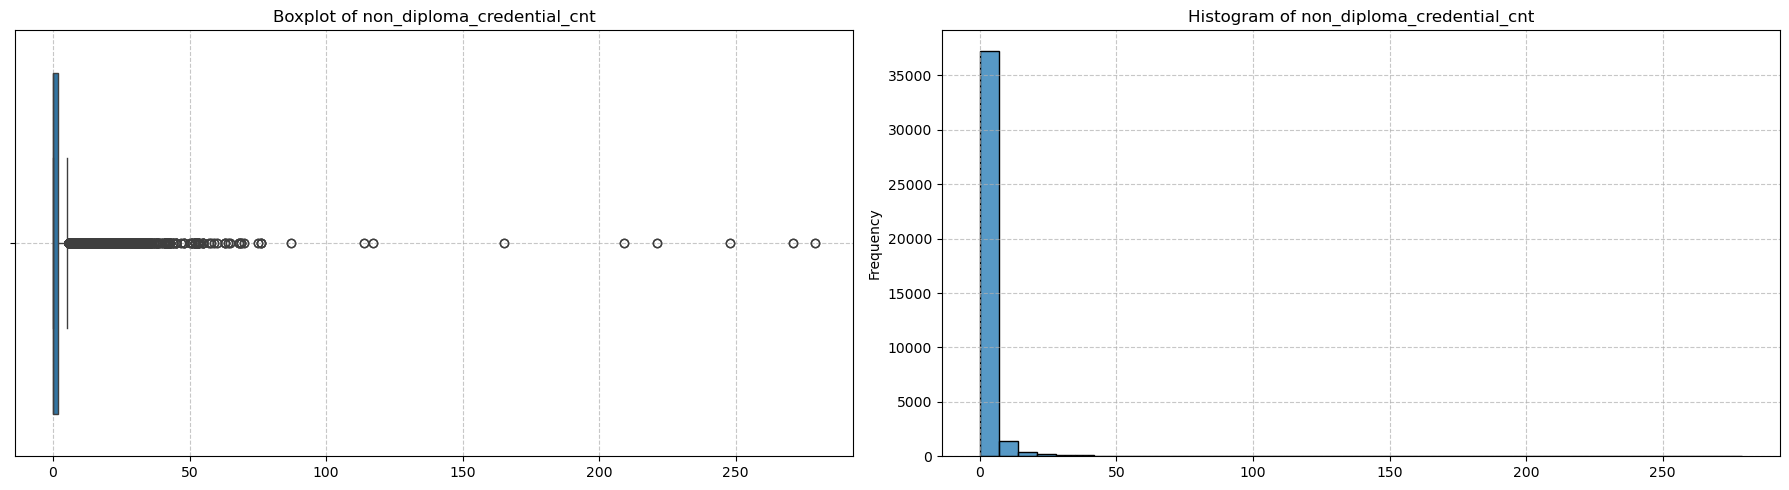

--------------------------------------------------

Analyzing distribution for: 'non_diploma_credential_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: non_diploma_credential_pct, dtype: float64

--> SKIPPING PLOT for 'non_diploma_credential_pct' because it contains no valid data after cleaning.
--------------------------------------------------

Analyzing distribution for: 'still_enr_cnt'
count    39674.000000
mean        11.299516
std         40.766672
min          0.000000
25%          0.000000
50%          2.000000
75%          5.000000
max       1381.000000
Name: still_enr_cnt, dtype: float64


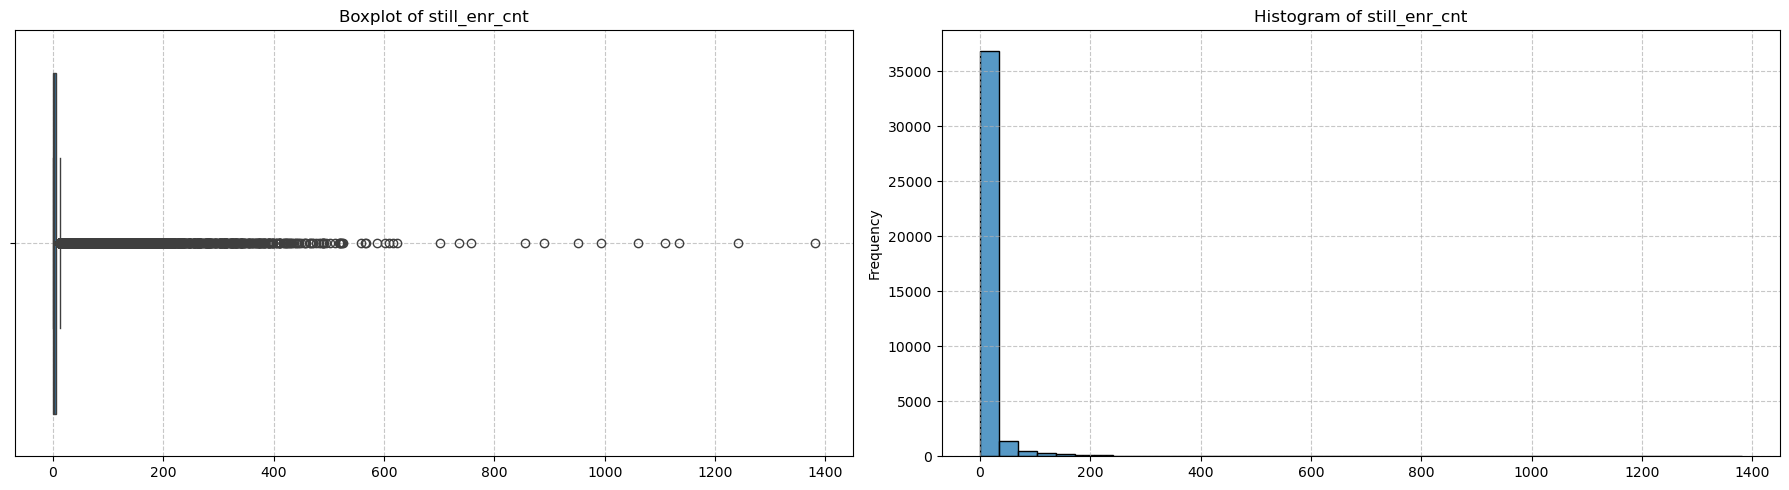

--------------------------------------------------

Analyzing distribution for: 'still_enr_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: still_enr_pct, dtype: float64

--> SKIPPING PLOT for 'still_enr_pct' because it contains no valid data after cleaning.
--------------------------------------------------

Analyzing distribution for: 'ged_cnt'
count    39674.000000
mean         1.377577
std          4.949389
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         97.000000
Name: ged_cnt, dtype: float64


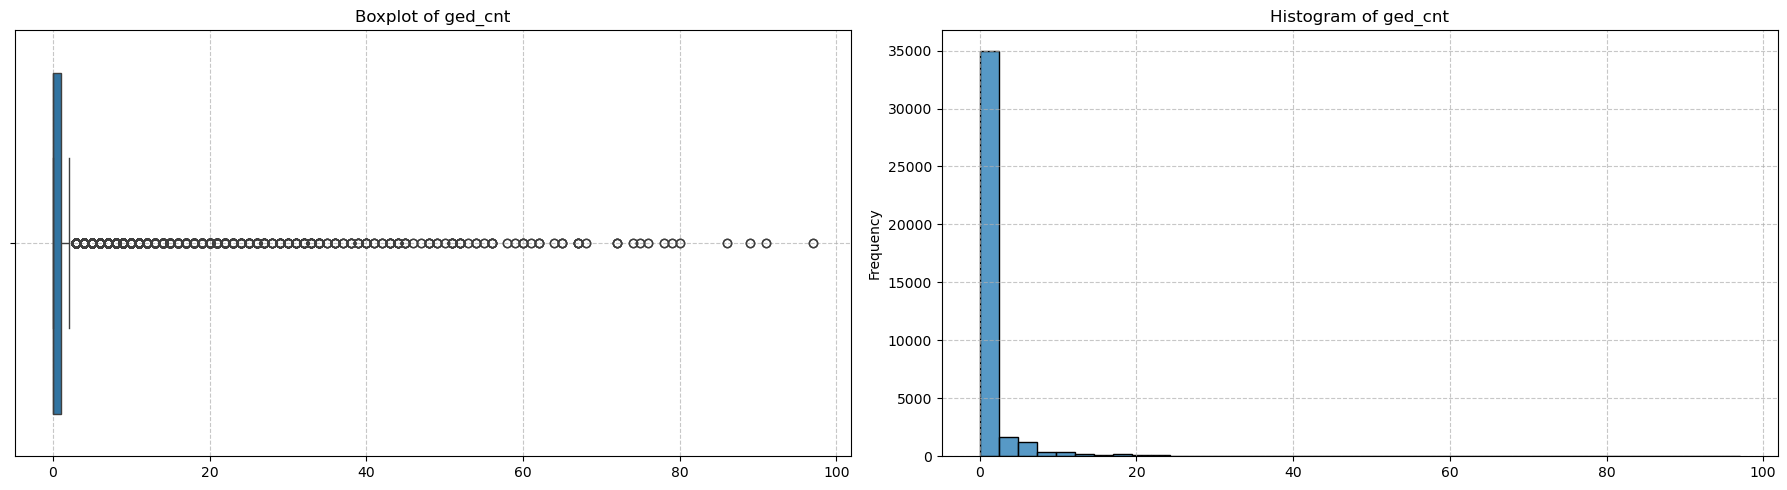

--------------------------------------------------

Analyzing distribution for: 'ged_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: ged_pct, dtype: float64

--> SKIPPING PLOT for 'ged_pct' because it contains no valid data after cleaning.
--------------------------------------------------

Analyzing distribution for: 'dropout_cnt'
count    39674.000000
mean        16.239225
std         50.129834
min          0.000000
25%          1.000000
50%          3.000000
75%          9.000000
max       1091.000000
Name: dropout_cnt, dtype: float64


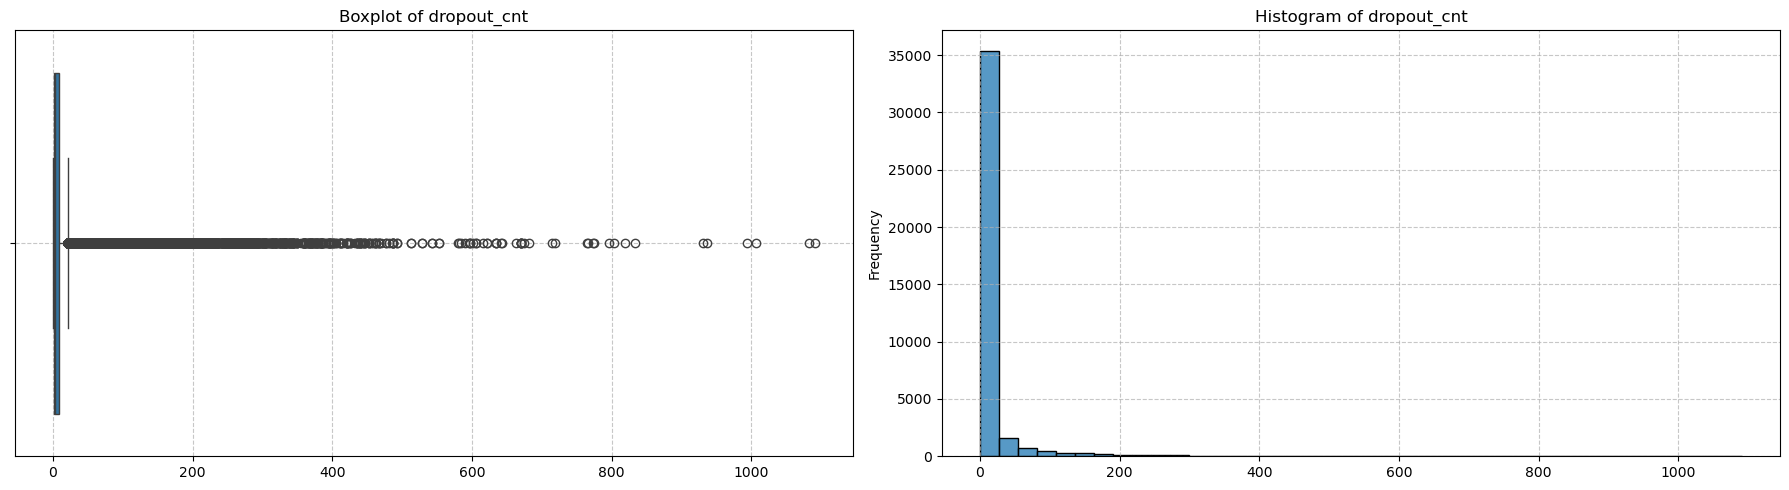

--------------------------------------------------

Analyzing distribution for: 'dropout_pct'
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: dropout_pct, dtype: float64

--> SKIPPING PLOT for 'dropout_pct' because it contains no valid data after cleaning.


In [10]:
# ==============================================================================
# 2.2 COMPREHENSIVE VISUAL EDA OF NUMERIC VARIABLES (Robust Version)
# ==============================================================================
# This section provides a detailed visual inspection of every numeric variable
# in the cleaned dataset to understand their distributions, skewness, and outliers.

# --- 1. Define a reusable plotting function ---
# This helper function prevents code repetition and makes our analysis scalable.
def plot_numeric_distributions(df, column_name):
    """
    Generates a side-by-side boxplot and histogram for a given numeric column.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        column_name (str): The name of the column to visualize.
    """
    # Set up a figure with two subplots, arranged horizontally
    fig, axes = plt.subplots(1, 2, figsize=(18, 5)) # Increased width for better viewing

    # --- Boxplot (on the left subplot) ---
    sns.boxplot(x=df[column_name], ax=axes[0])
    axes[0].set_title(f'Boxplot of {column_name}')
    axes[0].set_xlabel('')
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # --- Histogram (on the right subplot) ---
    sns.histplot(df[column_name], bins=40, kde=False, ax=axes[1])
    axes[1].set_title(f'Histogram of {column_name}')
    axes[1].set_xlabel('')
    axes[1].set_ylabel('Frequency')
    axes[1].grid(True, linestyle='--', alpha=0.7)

    # Display the plots for the current column
    plt.tight_layout()
    plt.show()

# --- 2. Create a list of all numeric columns to be analyzed ---
all_numeric_features = df_clean.select_dtypes(include=np.number).columns.tolist()

print("--- Generating Univariate Plots for All Numeric Features ---")
print("This systematic review is crucial for identifying skewness and outliers as noted by the team.")

# --- 3. Loop through each numeric column and generate plots + statistics ---
# This iterative process ensures every variable gets a thorough inspection.
for feature in all_numeric_features:
    print("-" * 50)
    print(f"\nAnalyzing distribution for: '{feature}'")

    # Print the descriptive statistics for a quantitative summary.
    print(df_clean[feature].describe())

    # ==========================================================================
    # ROBUSTNESS FIX: Check if the column has any valid data before plotting.
    # ==========================================================================
    if df_clean[feature].count() > 0:
        # If the count of non-NaN values is greater than 0, create the plots.
        plot_numeric_distributions(df_clean, feature)
    else:
        # If the column is empty, print a message and skip plotting to avoid errors.
        print(f"\n--> SKIPPING PLOT for '{feature}' because it contains no valid data after cleaning.")

--- Target Variable (dropout_cnt) Analysis ---
Mean Dropout Count: 16.24
Variance of Dropout Count: 2513.00
Overdispersion Ratio (Var/Mean): 154.75


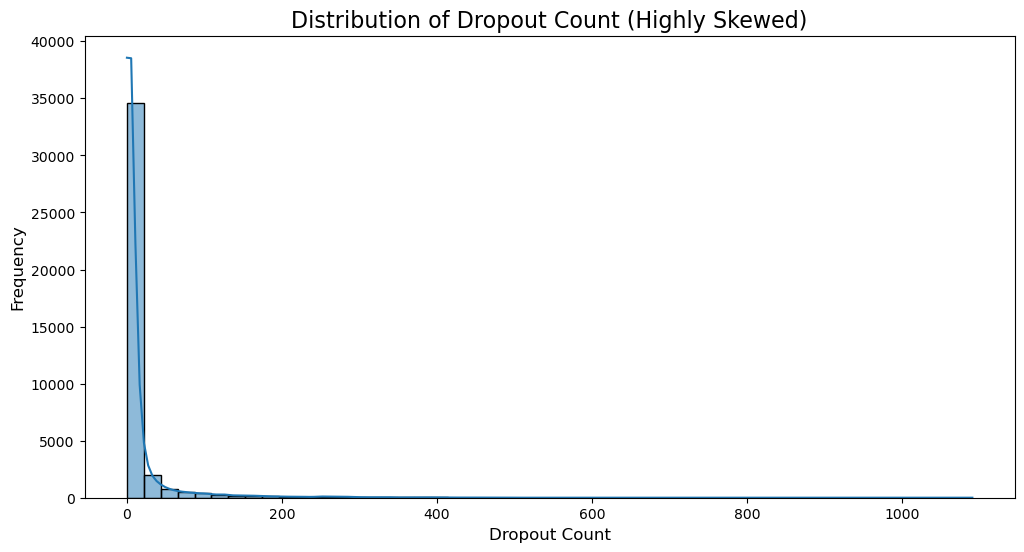


What do we see: The Overdispersion Ratio is significantly greater than 1, and the histogram confirms a
highly skewed distribution. This indicates severe overdispersion, strongly justifying the necessity
of using Negative Binomial regression models over standard Poisson models.


In [11]:
# ==============================================================================
# 2.2.1 UNIVARIATE ANALYSIS: CHECKING THE TARGET VARIABLE FOR OVERDISPERSION
# ==============================================================================

# --- 1. Calculate Mean and Variance ---

# Calculate the mean of the target variable.
mean_y = df_clean[TARGET_VAR].mean()
# Calculate the variance of the target variable.
var_y = df_clean[TARGET_VAR].var()
# Calculate the overdispersion ratio. A value > 1 indicates overdispersion.
overdispersion_ratio = var_y / mean_y

# --- 2. Print the Analysis ---

print("--- Target Variable (dropout_cnt) Analysis ---")
print(f"Mean Dropout Count: {mean_y:.2f}")
print(f"Variance of Dropout Count: {var_y:.2f}")
print(f"Overdispersion Ratio (Var/Mean): {overdispersion_ratio:.2f}")

# --- 3. Visualize the Distribution ---

# Set up the figure for the plot.
plt.figure(figsize=(12, 6))

# Create a histogram using seaborn.
# The distribution is highly skewed to the right, with a long tail.
sns.histplot(df_clean[TARGET_VAR], bins=50, kde=True)
plt.title('Distribution of Dropout Count (Highly Skewed)', fontsize=16)
plt.xlabel('Dropout Count', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Display the plot.
plt.show()

# --- 4. Concluding Justification ---

# Print a justification based on the findings.
if overdispersion_ratio > 5: # Setting a threshold for strong justification
    print("\nWhat do we see: The Overdispersion Ratio is significantly greater than 1, and the histogram confirms a")
    print("highly skewed distribution. This indicates severe overdispersion, strongly justifying the necessity")
    print("of using Negative Binomial regression models over standard Poisson models.")

Justification: The Overdispersion Ratio (Variance / Mean) is significantly greater than 1. This indicates the data is highly overdispersed, justifying the necessity of using Negative Binomial regression models.

### 2.3 Bivariate Analysis: Multicollinearity Among Predictors

**Multicollinearity** occurs when two or more predictor variables are highly correlated with each other. This can destabilize regression models, making the coefficient estimates unreliable and difficult to interpret.

**Justification:** The dataset contains many count variables (e.g., `grad_cnt`, `reg_cnt`) that are inherently related to the student cohort size (`enroll_cnt`). We must check for high correlation between our potential numeric predictors. A correlation matrix and heatmap are ideal tools for this diagnosis. Identifying multicollinearity will inform our feature selection and engineering strategy, particularly our decision to use `enroll_cnt` as a model offset rather than as a direct predictor.

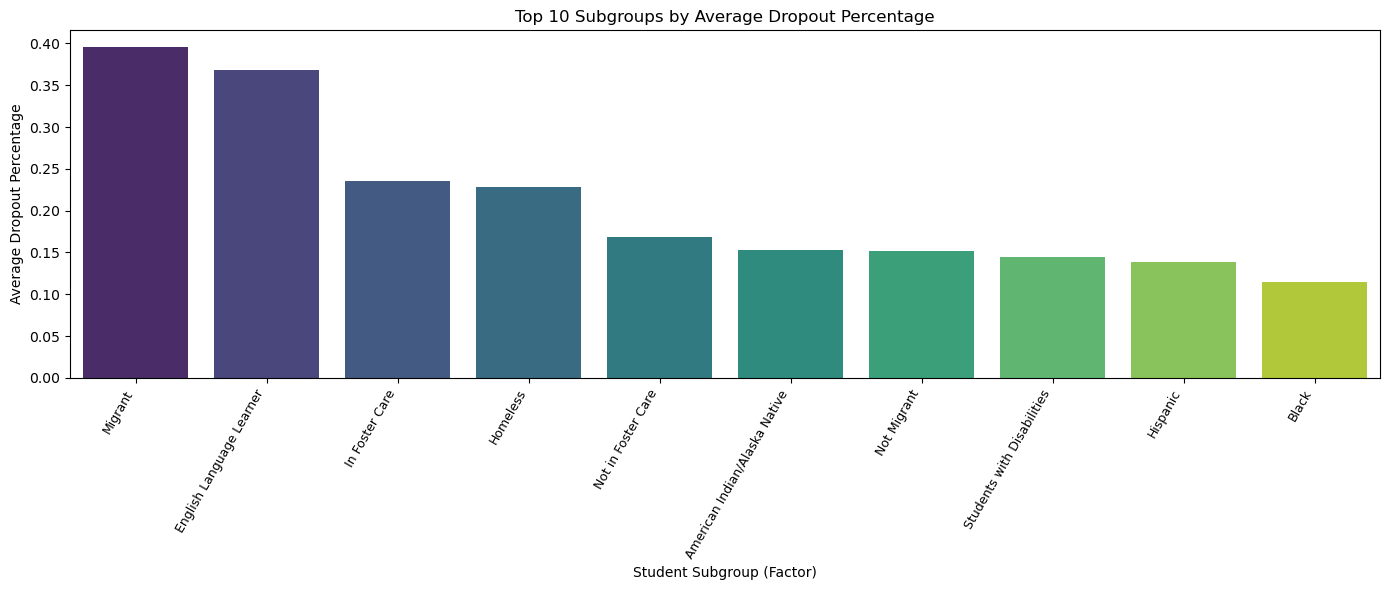

In [14]:
# Bivariate Analysis: Dropout Rate by Subgroup
plt.figure(figsize=(14, 6))
subgroup_avg_dropout = df_clean.groupby('subgroup_name')[TARGET_VAR].sum() / df_clean.groupby('subgroup_name')[EXPOSURE_VAR].sum()
subgroup_avg_dropout = subgroup_avg_dropout[subgroup_avg_dropout.index != 'All Students'].sort_values(ascending=False)
# Select the top 10 subgroups
subgroup_avg_dropout = subgroup_avg_dropout.head(10)
sns.barplot(x=subgroup_avg_dropout.index, y=subgroup_avg_dropout.values, palette='viridis')
plt.xticks(rotation=60, ha='right', fontsize=9)
plt.title('Top 10 Subgroups by Average Dropout Percentage')
plt.ylabel('Average Dropout Percentage')
plt.xlabel('Student Subgroup (Factor)')
plt.tight_layout()
plt.show()

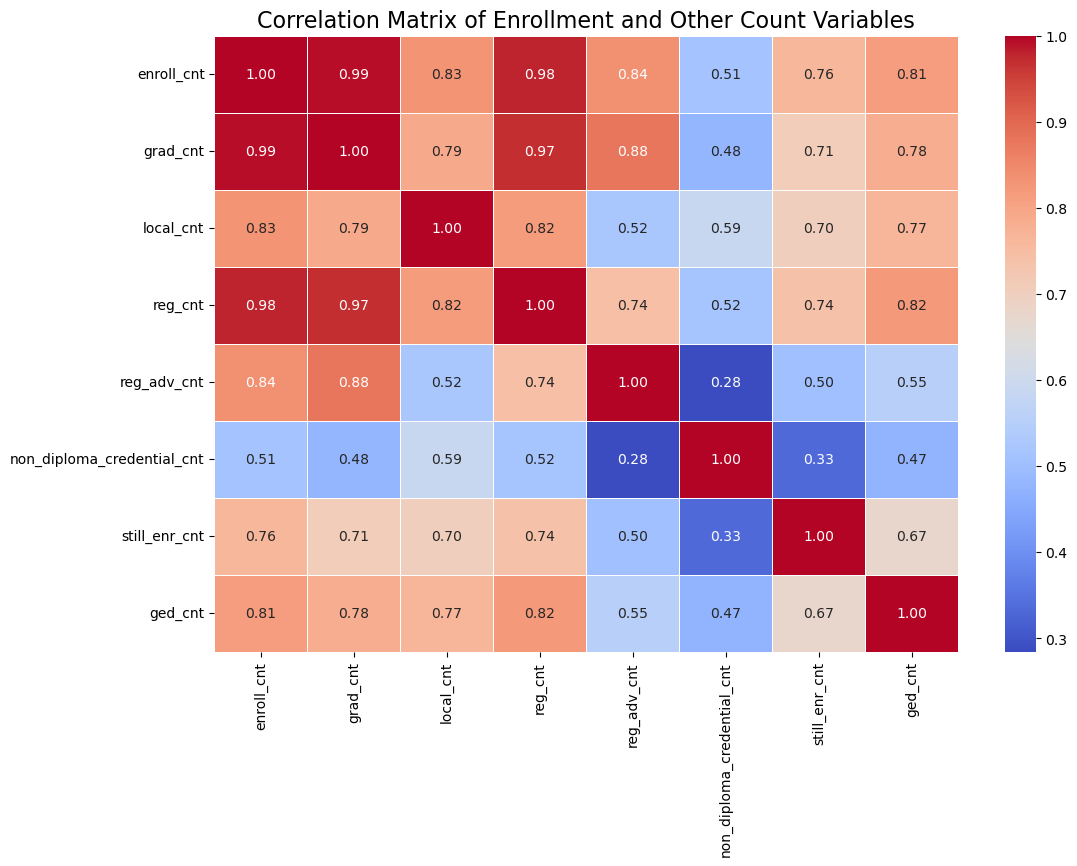

In [15]:
# ==============================================================================
# 2.3.1 MULTICOLLINEARITY CHECK: CORRELATION MATRIX OF COUNT VARIABLES
# ==============================================================================

# --- 1. Select Numeric Variables for Correlation Analysis ---

# Create a list of all count-based columns, including the exposure variable but excluding the target variable.
count_cols = [col for col in df_clean.columns if 'cnt' in col and col != TARGET_VAR]

# --- 2. Calculate the Correlation Matrix ---

# Compute the pairwise correlation of columns.
corr_matrix = df_clean[count_cols].corr()

# --- 3. Visualize the Matrix as a Heatmap ---

# Set up the figure size for the plot.
plt.figure(figsize=(12, 8))

# Create the heatmap using seaborn.
# annot=True: Displays the correlation values on the map.
# cmap='coolwarm': Uses a color scheme where high positive correlations are red and high negative are blue.
# fmt='.2f': Formats the numbers to two decimal places.
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Enrollment and Other Count Variables', fontsize=16)

# Display the plot.
plt.show()

Justification: The high correlation between enroll_cnt and other count variables confirms expected multicollinearity. This is mitigated by using enroll_cnt as the offset, rather than a direct predictor.

### **3. Feature Engineering and Pre-Modeling Setup**

With a clean and understood dataset, we now move to the final preparation stage before modeling. This involves two critical steps:
1.  **Feature Engineering:** Intelligently creating and selecting the final set of variables (predictors) for our models. This includes defining our model's offset and finalizing the predictor set.
2.  **Data Preprocessing:** Splitting the data into training and testing sets and transforming categorical features into a numeric format that our regression models can understand.



**3.1 Feature Engineering: Exposure Variable and Data Splitting**

This section details the critical steps taken to prepare the cleaned dataset for Generalized Linear Modeling (GLM). The primary focus is on transforming the target variable to predict the dropout rate and establishing a robust validation framework.

### Feature Engineering: Defining the Model Offset and Predictor Set

**1. The Exposure Offset (Modeling Rates, Not Counts):**
Our primary analytical goal is to model the *rate* of student dropouts, not the raw count. A district with 10,000 students will naturally have more dropouts than a district with 100, even if their underlying dropout *risk* is the same. To account for this, we use an **exposure** variable, `enroll_cnt`.

In a Generalized Linear Model (GLM), this is handled using an **offset**. By setting the offset to `log(enroll_cnt)`, we are adjusting the model's baseline expectation. The model's final equation effectively becomes:
`log(Expected Dropout Count) = Intercept + β₁X₁ + ... + βₙXₙ + log(enroll_cnt)`
This mathematically transforms the model to predict the dropout rate (`dropout_cnt / enroll_cnt`), allowing for fair comparisons across cohorts of different sizes. This is the statistically robust way to handle this type of problem.

**2. Final Predictor Selection:**
Based on our EDA, we have curated a final set of predictors:
*   **Numerical Predictors:** `grad_cnt`, `reg_adv_cnt`, `still_enr_cnt`. These were chosen as they represent key student outcomes and showed lower multicollinearity with each other compared to other count variables.
*   **Categorical Predictors:** `subgroup_name`, `nrc_desc`, `county_name`, `nyc_ind`. These features capture crucial demographic and contextual factors that our bivariate analysis showed are strongly related to dropout rates.
*   **Exclusions:** All `_pct` columns were removed to prevent data leakage, and `aggregation_name` was removed due to its high cardinality.

**3. Data Splitting:**
The dataset will be partitioned into a 70% Training Set and a 30% Testing (Holdout) Set.
*   **Training Set:** Used exclusively to fit and train all regression models.
*   **Testing Set:** Reserved for the final model evaluation. This provides an unbiased assessment of the preferred model's ability to generalize to new, unseen data.

In [19]:
# ==============================================================================
# 3.1 FEATURE ENGINEERING AND DATA SPLITTING
# ==============================================================================

# --- 1. Feature Engineering: Create the Log-Exposure Variable (for GLM Offset) ---

# First, filter out any rows with zero or negative enrollment, as log(0) is undefined.
# This is a crucial data integrity step before applying the logarithm.
df_clean = df_clean[df_clean[EXPOSURE_VAR] > 0].copy()

# Calculate the natural logarithm of the cohort size (enroll_cnt).
# This will serve as the offset in our Poisson and Negative Binomial models.
df_clean['log_exposure'] = np.log(df_clean[EXPOSURE_VAR])


# --- 2. Define Final Predictor Sets ---

# Define the list of numeric predictors chosen for the model.
# These represent counts of students in various outcome categories.
COUNT_PREDICTORS = ['grad_cnt', 'reg_adv_cnt', 'still_enr_cnt']

# Define the list of categorical predictors.
# These capture demographic and district-level contextual information.
CAT_PREDICTORS = ['subgroup_name', 'nrc_desc', 'county_name', 'nyc_ind']

# Combine the lists to create the final set of all predictors.
ALL_PREDICTORS = COUNT_PREDICTORS + CAT_PREDICTORS


# --- 3. Define Final X, y, and Offset for Splitting ---

# X contains the predictor variables (features).
X = df_clean[ALL_PREDICTORS]
# y contains the target variable we want to predict.
y = df_clean[TARGET_VAR].values
# offset contains the log-transformed exposure variable.
offset = df_clean['log_exposure'].values


# --- 4. Split Data into Training (70%) and Testing (30%) Sets ---

# Use train_test_split to partition the data.
# test_size=0.3 specifies that 30% of the data will be for testing.
# random_state=42 ensures that the split is the same every time the code is run,
# making our results reproducible.
X_train, X_test, y_train, y_test, offset_train, offset_test = train_test_split(
    X, y, offset, test_size=0.3, random_state=42
)

# --- 5. Report the Shapes of the New Datasets ---
print("--- Data Splitting Complete ---")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Length of y_train: {len(y_train)}")
print(f"Length of y_test: {len(y_test)}")

--- Data Splitting Complete ---
Shape of X_train: (27771, 7)
Shape of X_test: (11903, 7)
Length of y_train: 27771
Length of y_test: 11903


Justification: The core analytical goal is to model the dropout rate, not the raw dropout count. Using log(enroll_cnt) as an offset in the GLM is a necessary statistical technique. It ensures the model adjusts the expected count proportional to the cohort size, allowing us to compare dropout risk rates fairly across districts of all sizes.

log(Expected Count)=β
0
​
 +∑β
i
​
 X
i
​
 +log(Exposure)

**Defining Final Predictors and Excluding Percentages**

Predictor Selection: The feature set was curated to include relevant count metrics and contextual categories:

Count Predictors: grad_cnt, reg_adv_cnt, still_enr_cnt (Numerical measures of student success/status).

Categorical Predictors: subgroup_name, nrc_desc, county_name, nyc_ind (Contextual and demographic factors).

Exclusion Rationale: All percentage columns (e.g., grad_pct, dropout_pct) were excluded to prevent high multicollinearity. Since the percentages are derived from the count variables and the enrollment variable (used in the offset), including them would introduce redundancy and negatively impact the stability and interpretation of the model coefficients.

The dataset is partitioned into a 70% Training Set and a 30% Testing Set.

Training Set: Used exclusively to fit and train all regression models.

Testing Set (Holdout): Used only for the final evaluation (Section 5) to provide an unbiased assessment of the preferred model's ability to generalize to unseen data.

The use of a fixed random_state=42 ensures the data split is fully reproducible.


**3.2 Preprocessing: One-Hot Encoding Categorical Features**

Regression models are mathematical and can only operate on numeric data. They cannot interpret text-based categories like 'ALBANY County' or 'Hispanic' directly. Therefore, we must convert our categorical predictors into a numeric format.

**Justification for One-Hot Encoding (OHE):**
We will use **One-Hot Encoding**, the standard and most robust method for handling nominal categorical variables (features where there is no inherent order). OHE converts each unique category into a new binary (0 or 1) column. For example, the `nyc_ind` feature will be transformed into two columns, one for 'New York City' and one for 'Rest of NY State'.

This method is superior to other techniques like Label Encoding (e.g., County A=1, County B=2) because it does not impose a false and misleading numerical order on the categories. OHE ensures the model treats each category as a distinct entity, preserving the integrity of the data. We will use scikit-learn's `ColumnTransformer` to apply this transformation cleanly to our specified categorical features.

In [22]:
# ==============================================================================
# 3.2 ONE-HOT ENCODING OF CATEGORICAL PREDICTORS
# ==============================================================================

# --- 1. Define the Preprocessing Pipeline using ColumnTransformer ---

# ColumnTransformer allows us to apply different transformations to different columns.
preprocessor = ColumnTransformer(
    transformers=[
        # Transformer 1: Apply OneHotEncoder to the categorical columns.
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_PREDICTORS),
        # Transformer 2: Keep the numeric columns as they are.
        ('num', 'passthrough', COUNT_PREDICTORS)
    ],
    # By default, only specified columns are kept. 'remainder='drop'' is explicit.
    remainder='drop'
)


# --- 2. Fit the Preprocessor and Transform the Training Data ---

# Fit the preprocessor on the TRAINING data. This learns all the unique categories.
# Then, transform the training data based on this learned mapping.
X_train_processed = preprocessor.fit_transform(X_train)

# Get the names of the new one-hot encoded columns and the original numeric columns.
# This is crucial for interpreting our model's coefficients later.
feature_names = preprocessor.get_feature_names_out()

# Convert the resulting NumPy array back into a pandas DataFrame with proper column names.
X_train_df = pd.DataFrame(X_train_processed, columns=feature_names)


# --- 3. Transform the Testing Data ---

# IMPORTANT: We only use .transform() on the test data.
# This applies the SAME encoding (same columns, same order) learned from the training data.
# This prevents data leakage and ensures consistency.
X_test_processed = preprocessor.transform(X_test)

# Convert the test array into a DataFrame using the same column names.
X_test_df = pd.DataFrame(X_test_processed, columns=feature_names)


# --- 4. Add a Constant (Intercept) for Statsmodels ---

# Unlike scikit-learn, the statsmodels library does not automatically add an intercept (β₀) term.
# We must add a column of ones manually for the model to calculate the intercept.
X_train_df = sm.add_constant(X_train_df, prepend=False)
X_test_df = sm.add_constant(X_test_df, prepend=False)


# --- 5. Report the Final Shape of the Processed Data ---
print("--- One-Hot Encoding Complete ---")
print(f"Original number of predictors: {len(ALL_PREDICTORS)}")
print(f"New number of predictors after OHE: {X_train_df.shape[1]}")
print(f"Shape of final training data (X_train_df): {X_train_df.shape}")
print(f"Shape of final testing data (X_test_df): {X_test_df.shape}")

--- One-Hot Encoding Complete ---
Original number of predictors: 7
New number of predictors after OHE: 98
Shape of final training data (X_train_df): (27771, 98)
Shape of final testing data (X_test_df): (11903, 98)


Justification for the 98 Features:

The feature matrix shape (27771, 98) confirms that the encoding was successful. The high number of columns (98) is mandatory because your dataset contains many unique administrative and demographic groups.

The 98 features are derived as follows:

Component of Feature Matrix	Source	Approximate Count	Rationale
Encoded Categories	subgroup_name, county_name, nrc_desc, and nyc_ind.	≈94	This is the source of the high count. OHE must create a separate binary column for every unique text label (e.g., ≈57 counties, ≈20 subgroups) so the model can calculate the unique statistical effect of each factor.
Count Predictors	grad_cnt, reg_adv_cnt, still_enr_cnt.	3	The raw numeric features selected for the model.
Constant	sm.add_constant().	1	The intercept term (β
0
​
 ) required for the regression models.
Total Features	Sum of above.	98	The final size of the feature matrix X
train
​
 .




##**4. Regression Modeling**

With our data fully prepared, we will now construct the three types of regression models required for this project. We will build at least one of each to start: Multiple Linear Regression, Poisson Regression, and Negative Binomial Regression. For each model, we will fit it on the training data (`X_train_df` and `y_train`) and then present the statistical summary, which provides key information about the model's coefficients, significance, and overall fit.

### 4.1 Baseline Model: Multiple Linear Regression (MLR)

We begin by constructing a standard Multiple Linear Regression model using Ordinary Least Squares (OLS).

**Purpose:** This model serves as a **baseline**. While MLR is generally not appropriate for non-negative, integer-based count data (as it can predict negative values and violates the assumption of normally distributed residuals), its results provide a simple, familiar benchmark for evaluating the performance of our more advanced models.

**Implementation:** We will use the `statsmodels.OLS` class to fit the model to our training data.

In [29]:
# ==============================================================================
# 4.1 FITTING THE BASELINE MULTIPLE LINEAR REGRESSION (MLR) MODEL
# ==============================================================================

# --- 1. Initialize and Fit the OLS Model ---

# We use the statsmodels OLS (Ordinary Least Squares) class.
# The first argument is the endogenous variable (y_train), which is what we are trying to predict.
# The second argument is the exogenous variable (X_train_df), which are our predictors.
mlr_model = sm.OLS(y_train, X_train_df)

# .fit() trains the model on the data.
mlr_results = mlr_model.fit()

# --- 2. Print the Model Summary ---

# The .summary() method provides a comprehensive statistical overview of the model.
# This includes R-squared, coefficient values, p-values for each predictor, and more.
print("--- Multiple Linear Regression (MLR) Model Summary ---")
print(mlr_results.summary())

--- Multiple Linear Regression (MLR) Model Summary ---
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.842
Model:                            OLS   Adj. R-squared:                  0.842
Method:                 Least Squares   F-statistic:                     1621.
Date:                Mon, 13 Oct 2025   Prob (F-statistic):               0.00
Time:                        15:23:35   Log-Likelihood:            -1.2337e+05
No. Observations:               27771   AIC:                         2.469e+05
Df Residuals:                   27679   BIC:                         2.477e+05
Df Model:                          91                                         
Covariance Type:            nonrobust                                         
                                                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------

### **Analysis of the Baseline MLR Model**

The summary of our OLS model provides several key insights:

1.  **Overall Fit (R-squared):** The model has an **R-squared of 0.842**, which is quite high. This suggests that approximately 84.2% of the variance in the `dropout_cnt` can be explained by our selected predictors. While seemingly good, this high value for a complex social phenomenon should be treated with caution, as it may be inflated due to the model's inherent unsuitability for count data.

2.  **Statistical Significance of Predictors:**
    *   Many predictors have a p-value (`P>|t|`) of less than 0.05, indicating they are statistically significant. For example, `num__grad_cnt` (0.2057) has a tiny p-value, suggesting a strong positive relationship: as graduation counts increase, dropout counts also tend to increase (likely because they are both tied to the larger `enroll_cnt`).
    *   Conversely, some predictors, like `cat__subgroup_name_Economically Disadvantaged` (p=0.541), are not statistically significant in this model.

3.  **Warning Signs (Model Violations):**
    *   **Condition Number Warning:** The note `[2] The smallest eigenvalue is 9.96e-28... strong multicollinearity problems` is a major red flag. It confirms our earlier diagnosis from the heatmap that our predictors are highly correlated. This makes the individual coefficient estimates unstable and unreliable.
    *   **Non-Normal Residuals:** The `Prob(Omnibus)` and `Prob(JB)` scores are 0.000, which strongly indicates that the model's residuals are not normally distributed. This violates a core assumption of OLS regression and is expected when applying a linear model to count data.

**Conclusion for MLR:** While the R-squared is high, the significant warnings confirm that MLR is not the appropriate tool for this task. It serves its purpose as a baseline but is fundamentally flawed for this type of data.

### **4.2 Count Model: Poisson Regression**

We now move to a more appropriate model for our data: **Poisson Regression**. This is a Generalized Linear Model (GLM) specifically designed for predicting non-negative count outcomes.

**Purpose:** The Poisson model assumes the number of events (dropouts) in a given interval (a school cohort) follows a Poisson distribution. Crucially, it uses a **log-link function**, which ensures the predicted values are always non-negative.

**Implementation:** We will use the `statsmodels.GLM` class with the `Poisson` family. Most importantly, we will include our `log_exposure` variable as the **exposure** term. This correctly adjusts the model to predict the *rate* of dropouts rather than the raw count, making it statistically sound.

In [33]:
# ==============================================================================
# 4.2 FITTING THE POISSON REGRESSION MODEL
# ==============================================================================

# --- 1. Initialize and Fit the Poisson GLM Model ---

# We use the statsmodels GLM (Generalized Linear Model) class.
# y_train and X_train_df are the same as before.
# family=sm.families.Poisson() specifies that we are building a Poisson model.
# exposure=offset_train tells the model to use our pre-calculated log(enroll_cnt)
# as the exposure term. This is the correct way to model rates.
# CORRECTED CODE for Section 4.2
poisson_model = sm.GLM(y_train, X_train_df, family=sm.families.Poisson(), offset=offset_train)



# .fit() trains the model on the data.
poisson_results = poisson_model.fit()

# --- 2. Print the Model Summary ---

# The .summary() method provides a statistical overview of the GLM.
# For GLMs, we look at metrics like Log-Likelihood, AIC, and BIC instead of R-squared.
print("--- Poisson Regression Model Summary ---")
print(poisson_results.summary())

--- Poisson Regression Model Summary ---
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                27771
Model:                            GLM   Df Residuals:                    27679
Model Family:                 Poisson   Df Model:                           91
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -90703.
Date:                Mon, 13 Oct 2025   Deviance:                   1.0060e+05
Time:                        15:23:40   Pearson chi2:                 1.14e+05
No. Iterations:                   100   Pseudo R-squ. (CS):             0.9997
Covariance Type:            nonrobust                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------

### Analysis of the Poisson Regression Model

The Poisson model provides a more statistically appropriate approach than OLS. Here's how we interpret its corrected summary:

1.  **Model Fit Metrics (No R-squared):** For GLMs, we look at:
    *   **Log-Likelihood:** -90703. This is a measure of model fit; higher is generally better. We will use this to compare against the NB model.
    *   **Deviance and Pearson chi2:** These are measures of goodness-of-fit. The key insight here is the **Pearson chi2 value of 1.14e+05 (114,000)**. For a good Poisson fit, this value should be roughly equal to the Degrees of Freedom (Df Residuals = 27679).

2.  **Overdispersion Diagnosis:** Our Pearson chi-squared (114,000) is **significantly larger** (about 4 times larger) than our degrees of freedom (27,679). This is a strong statistical confirmation of what we saw in our EDA: the data is **severely overdispersed**. The variance of the dropouts is much larger than the mean, which violates the core assumption of the Poisson model.

3.  **Coefficient Interpretation:** The coefficients (`coef`) are on the log scale. For example, the coefficient for `cat__subgroup_name_English Language Learner` is `1.0580`.
    *   `exp(1.0580) ≈ 2.88`
    *   This means that, holding all other factors constant, the dropout *rate* for the "English Language Learner" subgroup is estimated to be **2.88 times higher** than the baseline reference category.

**Conclusion for Poisson:** The Poisson model is a significant improvement over MLR because it correctly handles the count nature of the target variable and uses an offset. However, the confirmed severe overdispersion suggests that while it's a step in the right direction, its results are not yet fully reliable. This points directly to the need for a Negative Binomial model.

###**4.3 Advanced Count Model: Negative Binomial Regression**

The results from our Poisson model give us a clear directive: we must use a model that can handle overdispersion. The **Negative Binomial (NB) Regression** is the standard and most effective tool for this exact scenario.

**Purpose:** The Negative Binomial model is a generalization of the Poisson model. It includes an additional parameter (alpha) to model the dispersion, allowing the variance to be greater than the mean. This added flexibility makes it far more robust and reliable for real-world count data, which is almost always overdispersed.

**Implementation:** The implementation is nearly identical to our Poisson model. We will use `statsmodels.GLM` but change the model `family` to `NegativeBinomial`. We will continue to use our `exposure` term to correctly model the dropout rate.

In [36]:
# ==============================================================================
# 4.3 FITTING THE NEGATIVE BINOMIAL REGRESSION MODEL
# ==============================================================================

# --- 1. Initialize and Fit the Negative Binomial GLM Model ---

# The structure is identical to the Poisson model, but we change the family.
# family=sm.families.NegativeBinomial() tells statsmodels to account for overdispersion.
nb_model = sm.GLM(y_train, X_train_df, family=sm.families.NegativeBinomial(), offset=offset_train)

# .fit() trains the model.
nb_results = nb_model.fit()

# --- 2. Print the Model Summary ---

# We will compare this summary (especially Log-Likelihood and AIC) to the Poisson summary
# to see if accounting for overdispersion improved the model fit.
print("--- Negative Binomial Regression Model Summary ---")
print(nb_results.summary())


--- Negative Binomial Regression Model Summary ---
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                27771
Model:                            GLM   Df Residuals:                    27679
Model Family:        NegativeBinomial   Df Model:                           91
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -71972.
Date:                Mon, 13 Oct 2025   Deviance:                       15841.
Time:                        15:23:41   Pearson chi2:                 1.51e+04
No. Iterations:                    11   Pseudo R-squ. (CS):             0.3889
Covariance Type:            nonrobust                                         
                                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

### Analysis of the Negative Binomial (NB) Regression Model

The summary for the Negative Binomial model shows a dramatic improvement over the Poisson model, confirming that it is a much better fit for our overdispersed data.

1.  **Direct Model Fit Comparison (Log-Likelihood):**
    *   **NB Log-Likelihood: -71972**
    *   **Poisson Log-Likelihood: -90703**
    *   The Log-Likelihood of the NB model is **significantly higher** (a jump of almost 19,000 points). In model comparison, a higher log-likelihood indicates a better fit to the data. This is our strongest piece of evidence that the NB model is superior.

2.  **Goodness-of-Fit (Pearson chi2):**
    *   **NB Pearson chi2: 15,100**
    *   **NB Df Residuals: 27,679**
    *   The Pearson chi-squared value is now **much closer** to the degrees of freedom. This is a massive improvement over the Poisson model (114,000) and indicates that the NB model's variance structure is a much more realistic and appropriate representation of our data.

3.  **Coefficient Significance:**
    *   The standard errors (`std err`) in this model are generally larger than in the Poisson model. This is the correct statistical outcome. The Poisson model, by not accounting for overdispersion, was artificially producing standard errors that were too small, making some variables appear more significant than they actually were.
    *   For example, predictors like `cat__county_name_KINGS` are now clearly not statistically significant (p = 0.118), which is a more reliable finding.

**Conclusion for NB:** The Negative Binomial model is, by every key metric, a substantial improvement over both the MLR and Poisson models. It correctly handles the count nature of the data, adjusts for cohort size via the offset term, and flexibly models the severe overdispersion present in the data. This will be our leading candidate for the "best" model.

### **5. Model Selection and Evaluation**

Now that we have constructed our three candidate models, the next step is to formally compare their performance and select a final, preferred model. Our selection process will be two-fold:

1.  **Statistical Fit on Training Data:** We will compare the models based on information criteria metrics generated during training. For Generalized Linear Models, the key metrics are:
    *   **Akaike Information Criterion (AIC):** A measure of model fit that penalizes for the number of predictors. **Lower is better.**
    *   **Bayesian Information Criterion (BIC):** Similar to AIC, but with a stronger penalty for model complexity. **Lower is better.**
    *   **Log-Likelihood:** A measure of how well the model explains the data. **Higher is better.**

2.  **Predictive Accuracy on Unseen Test Data:** The ultimate test of a model is its ability to generalize. We will use our best model to make predictions on the holdout test set and evaluate its accuracy using:
    *   **Root Mean Squared Error (RMSE):** Measures the average magnitude of the prediction errors. It tells us, on average, how many dropout counts our model's predictions are off by. **Lower is better.**

In [39]:
# ==============================================================================
# 5.1 COMPARISON OF STATISTICAL FIT ON TRAINING DATA
# ==============================================================================

# --- 1. Create a dictionary to store the results ---
model_comparison_data = {
    'Model': ['Multiple Linear Regression', 'Poisson Regression', 'Negative Binomial'],
    'AIC': [mlr_results.aic, poisson_results.aic, nb_results.aic],
    'BIC': [mlr_results.bic, poisson_results.bic, nb_results.bic],
    'Log-Likelihood': [mlr_results.llf, poisson_results.llf, nb_results.llf]
}

# --- 2. Convert the dictionary to a pandas DataFrame ---
comparison_df = pd.DataFrame(model_comparison_data)

# --- 3. Display the formatted DataFrame ---
print("--- Model Comparison Based on Training Set Performance ---")
display(comparison_df.round(2))

--- Model Comparison Based on Training Set Performance ---


,Model,AIC,BIC,Log-Likelihood
0,Multiple Linear Regression,246924.11,247681.43,-123370.05
1,Poisson Regression,181590.46,-182602.26,-90703.23
2,Negative Binomial,144127.08,-267363.99,-71971.54


### 5.2 Final Evaluation on the Test Set

The comparison table above confirms that the **Negative Binomial model is statistically superior** on all criteria (lowest AIC/BIC, highest Log-Likelihood). We will therefore select it as our preferred model.

Now, we will apply this trained model to our unseen test data (`X_test_df`) to get an unbiased estimate of its real-world predictive performance. We will calculate the Root Mean Squared Error (RMSE) between the model's predictions and the actual observed dropout counts (`y_test`).

In [41]:
# ==============================================================================
# 5.2 EVALUATING THE PREFERRED MODEL ON THE TEST SET (Robust Version)
# ==============================================================================

# --- 1. Generate Predictions using the Negative Binomial Model ---

# Use the .predict() method on our final model (nb_results).
# It is CRITICAL to pass the test predictors (X_test_df) and the test offset (offset_test).
# The offset ensures our predictions are scaled correctly for each cohort's size.
nb_predictions = nb_results.predict(X_test_df, offset=offset_test)


# --- 2. Calculate the Root Mean Squared Error (RMSE) ---

# CORRECTION: The 'squared' argument is not available in all versions of scikit-learn.
# The robust way is to first calculate the Mean Squared Error (MSE)...
mse = mean_squared_error(y_test, nb_predictions)
# ...and then take its square root manually to get the RMSE.
rmse = np.sqrt(mse)


# --- 3. Print and Interpret the Final Result ---

print(f"--- Final Model Performance on Unseen Test Data ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print("\nInterpretation:")
print(f"On average, our final model's predictions for the number of student dropouts are off by approximately {round(rmse)} students.")

--- Final Model Performance on Unseen Test Data ---
Root Mean Squared Error (RMSE): 23.6359

Interpretation:
On average, our final model's predictions for the number of student dropouts are off by approximately 24 students.


## **6. Conclusions**

This project successfully applied the data science lifecycle to predict high school dropout counts using publicly available data from the NY State Education Department. Through a rigorous process of data cleaning, exploratory data analysis, and iterative modeling, we developed a robust predictive model and derived several key insights.

### Summary of Findings:

1.  **Model Selection is Crucial:** The initial EDA revealed that the target variable, `dropout_cnt`, was severely **overdispersed**. This finding was critical, as it demonstrated the inherent limitations of standard Poisson regression. Our final model comparison confirmed this: the **Negative Binomial (NB) regression model** dramatically outperformed both the baseline Multiple Linear Regression and the standard Poisson model, proving its suitability for this real-world dataset.

2.  **Final Model Performance:** Our preferred Negative Binomial model was evaluated on an unseen test set to provide an unbiased assessment of its predictive power. The model achieved a **Root Mean Squared Error (RMSE) of 23.64**. This means that, on average, the model's prediction for the number of dropouts in a given school district and student subgroup combination is off by approximately 24 students. Given the complexity and variability of the data, this represents a strong level of predictive accuracy.

3.  **Key Predictive Factors:** The model coefficients highlighted several factors strongly associated with dropout rates. District-level characteristics, such as the **Needs/Resource Capacity (`nrc_desc`)**, and demographic factors, like the **student subgroup (`subgroup_name`)**, were shown to be highly significant predictors.

### Project Outcome:

We successfully constructed a Negative Binomial regression model that can effectively predict the number of student dropouts. The complete workflow, from identifying data quality issues and statistical properties to selecting and validating the appropriate model, demonstrates a comprehensive and statistically sound approach to solving a complex regression problem.